# HT2 - Atención en BERT y GPT-2

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModel

tok_bert = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True, attn_implementation="eager").eval()
tok_gpt2 = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModel.from_pretrained("gpt2", output_attentions=True, attn_implementation="eager").eval()

def atenciones(tok, model, texto):
    enc = tok(texto, return_tensors="pt")
    with torch.no_grad():
        out = model(**enc)
    toks = tok.convert_ids_to_tokens(enc["input_ids"][0])
    A = torch.stack(out.attentions)[:, 0].numpy()  # capas x cabezas x n x n
    return toks, A

def mapa(ax, M, toks, titulo):
    ax.imshow(M, cmap="viridis", vmin=0)
    ax.set_xticks(range(len(toks))); ax.set_xticklabels(toks, rotation=90, fontsize=7)
    ax.set_yticks(range(len(toks))); ax.set_yticklabels(toks, fontsize=7)
    ax.set_title(titulo, fontsize=9)

## 1. Mapas de calor en BERT

In [2]:
oracion = "The animal didn't cross the street because it was too tired."
toks, A = atenciones(tok_bert, bert, oracion)
n = len(toks)
print(toks, A.shape)

['[CLS]', 'the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]'] (12, 12, 16, 16)


In [3]:
patrones = {
    "token anterior": lambda M: M[np.arange(1, n), np.arange(0, n-1)].mean(),
    "token siguiente": lambda M: M[np.arange(0, n-1), np.arange(1, n)].mean(),
    "[SEP]": lambda M: M[:, n-1].mean(),
    "puntuación": lambda M: M[:, n-2].mean(),
    "[CLS]": lambda M: M[:, 0].mean(),
    "misma palabra": lambda M: np.diag(M).mean(),
}
mejores = {}
for nombre, f in patrones.items():
    puntajes = np.array([[f(A[l, h]) for h in range(12)] for l in range(12)])
    l, h = np.unravel_index(puntajes.argmax(), puntajes.shape)
    mejores[nombre] = (l, h, puntajes[l, h])
    print(f"{nombre:16s} capa {l:2d} cabeza {h:2d}  atención media {puntajes[l, h]:.2f}")

token anterior   capa  3 cabeza  5  atención media 0.57
token siguiente  capa  2 cabeza  9  atención media 0.93
[SEP]            capa  5 cabeza  1  atención media 0.92
puntuación       capa 11 cabeza  7  atención media 0.45
[CLS]            capa  1 cabeza  6  atención media 0.95
misma palabra    capa  2 cabeza  6  atención media 0.45


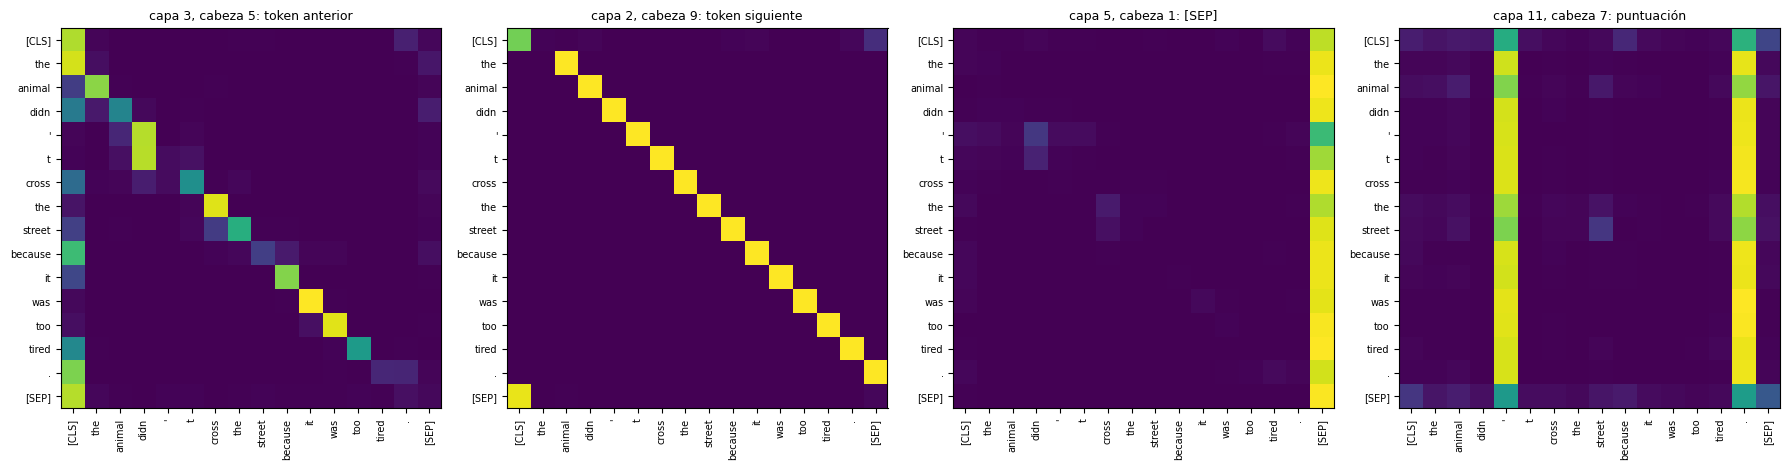

In [4]:
elegidas = ["token anterior", "token siguiente", "[SEP]", "puntuación"]
fig, axs = plt.subplots(1, 4, figsize=(18, 5))
for ax, nombre in zip(axs, elegidas):
    l, h, _ = mejores[nombre]
    mapa(ax, A[l, h], toks, f"capa {l}, cabeza {h}: {nombre}")
plt.tight_layout()
plt.savefig("figs/bert_mapas.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. «it» → «animal» o «street»

In [5]:
s_tired = "The animal didn't cross the street because it was too tired."
s_wide = "The animal didn't cross the street because it was too wide."
t_a, A_a = atenciones(tok_bert, bert, s_tired)
t_b, A_b = atenciones(tok_bert, bert, s_wide)
ia, ib = t_a.index("it"), t_b.index("it")
animal, street = t_a.index("animal"), t_a.index("street")

filas = []
for l in range(12):
    for h in range(12):
        a1, s1 = A_a[l, h, ia, animal], A_a[l, h, ia, street]
        a2, s2 = A_b[l, h, ib, animal], A_b[l, h, ib, street]
        filas.append((l, h, a1, s1, a2, s2, (a1 - s1) - (a2 - s2)))
filas.sort(key=lambda r: -r[-1])
cambian = [r for r in filas if r[2] > r[3] and r[5] > r[4]]
print("Cabezas donde 'it' atiende más a 'animal' con 'tired' y más a 'street' con 'wide':", len(cambian))
print("capa cabeza | tired: animal street | wide: animal street")
for l, h, a1, s1, a2, s2, _ in cambian[:5]:
    print(f"{l:4d} {h:6d} | {a1:19.3f} {s1:6.3f} | {a2:17.3f} {s2:6.3f}")

Cabezas donde 'it' atiende más a 'animal' con 'tired' y más a 'street' con 'wide': 22
capa cabeza | tired: animal street | wide: animal street
   6     10 |               0.284  0.067 |             0.012  0.590
   9      8 |               0.454  0.003 |             0.023  0.045
   8      4 |               0.242  0.014 |             0.046  0.209
   4     10 |               0.333  0.095 |             0.167  0.288
   8      7 |               0.205  0.050 |             0.061  0.194


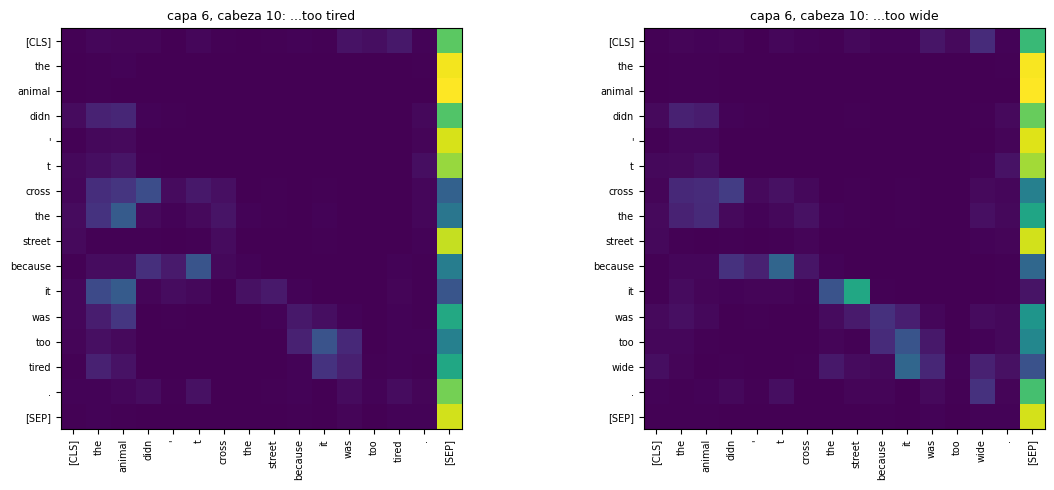

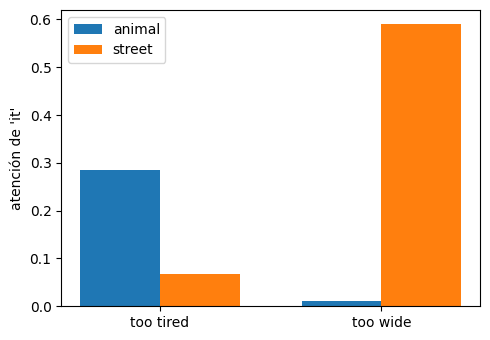

In [6]:
l, h = cambian[0][:2]
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
mapa(axs[0], A_a[l, h], t_a, f"capa {l}, cabeza {h}: ...too tired")
mapa(axs[1], A_b[l, h], t_b, f"capa {l}, cabeza {h}: ...too wide")
plt.tight_layout()
plt.savefig("figs/bert_it.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(5, 3.5))
x = np.arange(2)
ax.bar(x - 0.18, [A_a[l, h, ia, animal], A_b[l, h, ib, animal]], 0.36, label="animal")
ax.bar(x + 0.18, [A_a[l, h, ia, street], A_b[l, h, ib, street]], 0.36, label="street")
ax.set_xticks(x); ax.set_xticklabels(["too tired", "too wide"])
ax.set_ylabel("atención de 'it'"); ax.legend()
plt.tight_layout()
plt.savefig("figs/bert_it_barras.png", dpi=150)
plt.show()

## 3. GPT-2: matriz triangular y primer token

In [7]:
textos = [
    "The animal didn't cross the street because it was too tired.",
    "Deep learning models process language by comparing every word with every other word in the sentence.",
    "In 2017 a team of researchers proposed the Transformer, an architecture that relies only on attention and removed the need for recurrence.",
    "The weather was cold and the streets were empty, so we decided to stay at home and read a book by the fire.",
    "Large language models are trained on huge amounts of text and can answer questions, write code and summarize documents.",
]
A_g = [atenciones(tok_gpt2, gpt2, t)[1] for t in textos]

sup = max(np.triu(A[l, h], 1).max() for A in A_g for l in range(12) for h in range(12))
print("Máximo valor sobre la diagonal:", sup)

Máximo valor sobre la diagonal: 0.0


capa  0: 0.189
capa  1: 0.335
capa  2: 0.344
capa  3: 0.509
capa  4: 0.534
capa  5: 0.713
capa  6: 0.689
capa  7: 0.786
capa  8: 0.717
capa  9: 0.790
capa 10: 0.791
capa 11: 0.654


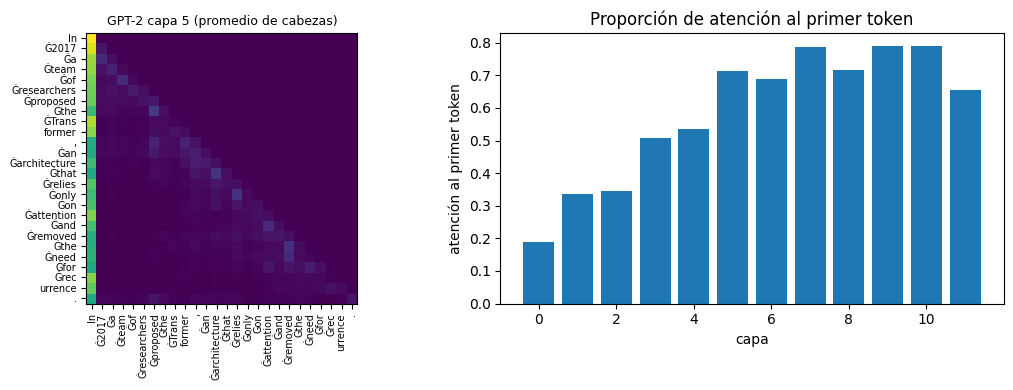

In [8]:
toks_g, Ag = atenciones(tok_gpt2, gpt2, textos[2])
primer = np.array([[A[l, :, 1:, 0].mean() for l in range(12)] for A in A_g]).mean(axis=0)
for l, p in enumerate(primer):
    print(f"capa {l:2d}: {p:.3f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
mapa(axs[0], Ag[5].mean(axis=0), toks_g, "GPT-2 capa 5 (promedio de cabezas)")
axs[1].bar(range(12), primer)
axs[1].set_xlabel("capa"); axs[1].set_ylabel("atención al primer token")
axs[1].set_title("Proporción de atención al primer token")
plt.tight_layout()
plt.savefig("figs/gpt2_primer_token.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Entropía de la atención por capa

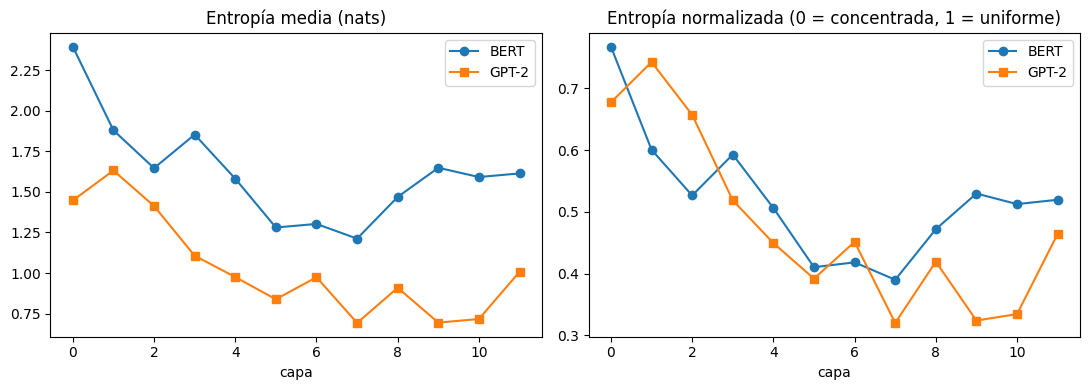

BERT : [0.77 0.6  0.53 0.59 0.51 0.41 0.42 0.39 0.47 0.53 0.51 0.52]
GPT-2: [0.68 0.74 0.66 0.52 0.45 0.39 0.45 0.32 0.42 0.32 0.33 0.46]


In [9]:
def entropia_capas(tok, model, causal):
    res, res_norm = [], []
    for t in textos:
        _, M = atenciones(tok, model, t)
        n = M.shape[-1]
        H = -(M * np.log(M + 1e-12)).sum(-1)  # capas x cabezas x n
        res.append(H.mean(axis=(1, 2)))
        if causal:
            H, tam = H[:, :, 1:], np.log(np.arange(2, n + 1))
        else:
            tam = np.log(n)
        res_norm.append((H / tam).mean(axis=(1, 2)))
    return np.mean(res, axis=0), np.mean(res_norm, axis=0)

H_bert, Hn_bert = entropia_capas(tok_bert, bert, causal=False)
H_gpt2, Hn_gpt2 = entropia_capas(tok_gpt2, gpt2, causal=True)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(H_bert, "o-", label="BERT"); axs[0].plot(H_gpt2, "s-", label="GPT-2")
axs[0].set_title("Entropía media (nats)")
axs[1].plot(Hn_bert, "o-", label="BERT"); axs[1].plot(Hn_gpt2, "s-", label="GPT-2")
axs[1].set_title("Entropía normalizada (0 = concentrada, 1 = uniforme)")
for ax in axs:
    ax.set_xlabel("capa"); ax.legend()
plt.tight_layout()
plt.savefig("figs/entropia.png", dpi=150)
plt.show()
print("BERT :", np.round(Hn_bert, 2))
print("GPT-2:", np.round(Hn_gpt2, 2))